# Industry Project: Customer Segmentation with Clustering (Production-Style)

> **Who is this notebook for?** Beginners who know *what* clustering is (or not!) and want to see how it is used in a real company.
> Every step is explained in plain English and the code is heavily commented.

---

### How this notebook is different from `01_clustering.ipynb`

| `01_clustering.ipynb` | This notebook |
|---|---|
| How K-Means / DBSCAN work, from scratch | How a marketing team actually uses clusters |
| `make_blobs` toy points | Raw **transaction logs** turned into customer features |
| Ends with a scatter plot | Ends with **named segments**, a **saved model**, and **new customers assigned automatically** |

### The business problem

You work at an online store. Marketing sends the **same email to everyone**, and results are poor.
The marketing director asks: *"Can you split our customers into a few groups that behave differently, so we can treat each group differently?"*

There is **no label** (nobody tells us the "right" group). This is **unsupervised learning**.

### Table of Contents
1. Setup
2. Raw data: one row per transaction
3. From transactions to customers: RFM features
4. Prepare the features (skew, outliers, scaling)
5. How many segments? Use metrics *and* business sense
6. Fit the final model inside a pipeline
7. Profile and **name** the segments
8. Visualise the segments
9. Check stability: would we get the same segments again?
10. Save the model and assign new customers
11. Turn segments into actions
12. Summary

---
## 1. Setup

In [1]:
import json
import logging
import tempfile
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("segmentation")

RANDOM_STATE = 42
SNAPSHOT_DATE = pd.Timestamp("2026-09-30")   # "today" for the analysis

---
## 2. Raw data: one row per transaction

Real e-commerce data is a **log of orders**, not a neat table of customers.
We simulate 12 months of orders for 3,000 customers who secretly belong to different behaviour types (the model doesn't know these types; it must discover them).

In a company this would be: `pd.read_sql("SELECT customer_id, order_date, amount FROM orders WHERE ...", engine)`

In [2]:
def simulate_orders(n_customers: int = 3000, seed: int = RANDOM_STATE) -> pd.DataFrame:
    """Simulate an order log. Each hidden persona has its own buying habits."""
    rng = np.random.default_rng(seed)
    personas = {  # name: (share of customers, orders per year, avg order $, last-order recency in days)
        "loyal_big_spenders": (0.12, 25, 160, 10),
        "regulars":           (0.30, 10, 60, 25),
        "bargain_hunters":    (0.28, 6, 25, 45),
        "new_customers":      (0.15, 2, 55, 15),
        "lapsed":             (0.15, 3, 50, 220),
    }
    rows = []
    customer_ids = iter(range(10_000, 10_000 + n_customers))
    for name, (share, freq, avg_amount, recency) in personas.items():
        for _ in range(int(n_customers * share)):
            cid = next(customer_ids)
            n_orders = max(1, rng.poisson(freq))
            last_order_days_ago = min(364, int(rng.exponential(recency)))
            days_ago = last_order_days_ago + rng.integers(0, 365 - last_order_days_ago, n_orders)
            days_ago[0] = last_order_days_ago                       # make sure the last order is included
            amounts = rng.gamma(shape=2.0, scale=avg_amount / 2.0, size=n_orders).round(2)
            for d, amt in zip(days_ago, amounts):
                rows.append((cid, SNAPSHOT_DATE - pd.Timedelta(days=int(d)), amt))
    orders = pd.DataFrame(rows, columns=["customer_id", "order_date", "amount"])
    # Real-world mess: refunds recorded as negative amounts
    refund_idx = rng.choice(len(orders), 200, replace=False)
    orders.loc[refund_idx, "amount"] *= -1
    return orders.sample(frac=1, random_state=seed).reset_index(drop=True)   # shuffle like a real log


orders = simulate_orders()
print(f"{len(orders):,} orders from {orders['customer_id'].nunique():,} customers")
orders.head()

25,272 orders from 3,000 customers


,customer_id,order_date,amount
0,10038,2025-12-28,240.20
1,11604,2026-09-25,20.62
2,10950,2025-10-24,51.65
3,10486,2026-08-20,39.29
4,10320,2025-10-13,129.42


---
## 3. From transactions to customers: RFM features

**RFM** is the most widely used segmentation framework in retail and marketing (it predates machine learning!):

| Letter | Meaning | Question it answers |
|---|---|---|
| **R**ecency | Days since last purchase | Are they still active? |
| **F**requency | Number of purchases | How engaged are they? |
| **M**onetary | Total money spent | How valuable are they? |

We add one more: **average order value**, which separates "many small orders" from "few big orders".
This step, turning raw logs into one row per customer, is called **aggregation** and it's a core feature-engineering skill.

In [3]:
def build_rfm(order_log: pd.DataFrame, snapshot: pd.Timestamp) -> pd.DataFrame:
    """Aggregate an order log into one row of behavioural features per customer."""
    purchases = order_log[order_log["amount"] > 0]           # real purchases (refunds have amount < 0)
    log.info("Found %d refund rows", int((order_log["amount"] <= 0).sum()))
    rfm = purchases.groupby("customer_id").agg(
        last_order=("order_date", "max"),
        frequency=("order_date", "count"),                   # refunds are NOT counted as purchases
        gross_spend=("amount", "sum"),
    )
    # Monetary = NET revenue: refunds are subtracted. (Ignoring them would overstate what customers are worth.)
    net_spend = order_log.groupby("customer_id")["amount"].sum()
    rfm["monetary"] = net_spend.reindex(rfm.index).clip(lower=0)
    rfm["recency_days"] = (snapshot - rfm["last_order"]).dt.days
    rfm["avg_order_value"] = rfm["gross_spend"] / rfm["frequency"]
    return rfm[["recency_days", "frequency", "monetary", "avg_order_value"]]


rfm = build_rfm(orders, SNAPSHOT_DATE)
rfm.describe().round(1)

2026-10-21 15:54:02,134 | INFO | Found 200 refund rows


,recency_days,frequency,monetary,avg_order_value
count,2997.0,2997.0,2997.0,2997.0
mean,49.7,8.4,726.4,59.9
std,79.1,7.3,1245.6,44.8
min,0.0,1.0,0.0,0.9
25%,7.0,3.0,108.9,27.9
50%,21.0,6.0,225.0,48.6
75%,50.0,11.0,604.5,69.0
max,364.0,38.0,6549.8,246.9


---
## 4. Prepare the features (skew, outliers, scaling)

K-Means uses **distances**, so two problems must be fixed first:

1. **Different scales**: `monetary` goes up to thousands, `frequency` up to ~40. Without scaling, money would dominate everything. → `StandardScaler`.
2. **Skew**: a few huge spenders would pull clusters around. → apply `log1p` (log of 1 + x), which squashes big values.

Let's see the skew first.

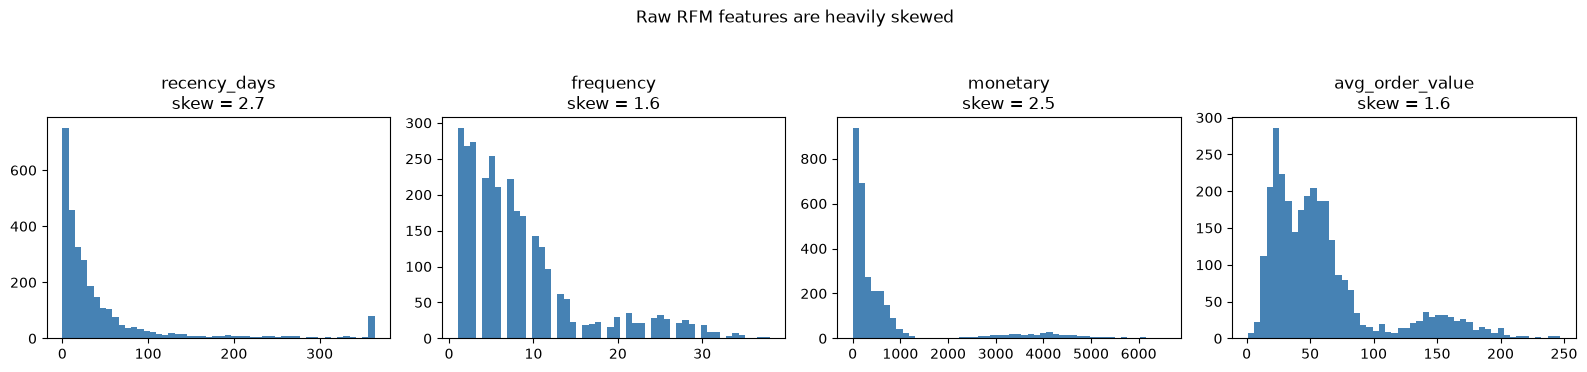

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, rfm.columns):
    ax.hist(rfm[col], bins=50, color="steelblue")
    ax.set_title(f"{col}\nskew = {rfm[col].skew():.1f}")
plt.suptitle("Raw RFM features are heavily skewed", y=1.05)
plt.tight_layout(); plt.show()

Skew far above 1 means a long tail. We put **log + scaling** into a pipeline so new customers are transformed identically later.

### Which features go into the clustering?
Notice that `monetary ≈ frequency × avg_order_value`. If we cluster on all three, the same information is counted **twice**, and K-Means would over-weight it. A common industry choice is to cluster on **recency, frequency and average order value**, and keep `monetary` for **describing** the segments afterwards (Section 7).

In [5]:
CLUSTER_FEATURES = ["recency_days", "frequency", "avg_order_value"]   # what K-Means sees
PROFILE_FEATURES = ["recency_days", "frequency", "monetary", "avg_order_value"]   # what humans read

# Step 1 of the pipeline: log-transform. Step 2: scale. (Step 3, KMeans, is added in Section 6)
preprocess = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])
X = preprocess.fit_transform(rfm[CLUSTER_FEATURES])
print("After log + scaling: mean ≈ 0, std ≈ 1 for every feature")
pd.DataFrame(X, columns=CLUSTER_FEATURES).describe().loc[["mean", "std"]].round(2)

After log + scaling: mean ≈ 0, std ≈ 1 for every feature


,recency_days,frequency,avg_order_value
mean,0.0,0.0,-0.0
std,1.0,1.0,1.0


---
## 5. How many segments? Use metrics *and* business sense

K-Means needs you to choose **k**, the number of clusters. Professionals look at several signals:

- **Inertia / elbow**: how tight clusters are. Always decreases with k; look for the "bend".
- **Silhouette score** (-1 to 1): how well each customer fits its own cluster vs. the nearest other cluster. Higher is better.
- **Calinski-Harabasz**: ratio of between-cluster to within-cluster spread. Higher is better.
- **Business sense**: marketing cannot run 15 different campaigns. Usually **3 to 7** segments are actionable.

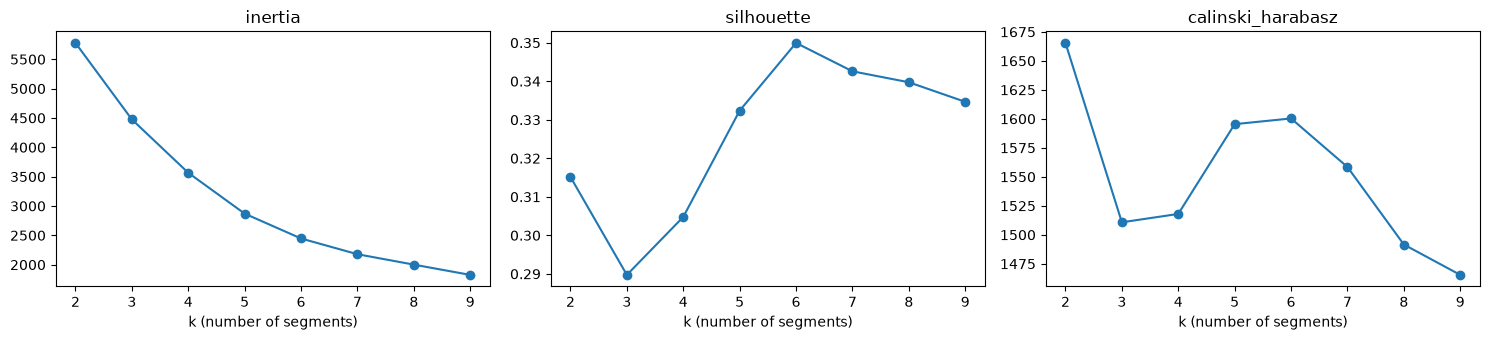

,inertia,silhouette,calinski_harabasz
k,,,
2,5778.047,0.315,1665.448
3,4474.938,0.290,1510.779
4,3565.704,0.305,1517.996
5,2869.855,0.332,1595.417
6,2446.371,0.350,1600.328
7,2178.423,0.343,1558.437
8,2001.013,0.340,1491.607
9,1826.142,0.335,1465.425


In [6]:
k_values = range(2, 10)
scores = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    scores.append({"k": k, "inertia": km.inertia_,
                   "silhouette": silhouette_score(X, km.labels_, sample_size=2000, random_state=RANDOM_STATE),
                   "calinski_harabasz": calinski_harabasz_score(X, km.labels_)})
scores = pd.DataFrame(scores).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, scores.columns):
    ax.plot(scores.index, scores[col], "o-")
    ax.set_title(col); ax.set_xlabel("k (number of segments)")
plt.tight_layout(); plt.show()
scores.round(3)

In [7]:
# Choose k with a common, defensible rule:
#   1. only consider the "actionable" range 3-7 segments,
#   2. take the SMALLEST k whose silhouette is within 0.02 of the best one.
#      (Fewer segments = simpler campaigns. A tiny metric gain is not worth an extra campaign.)
actionable = scores.loc[3:7, "silhouette"]
good_enough = actionable[actionable >= actionable.max() - 0.02]
best_k = int(good_enough.index.min())
print(f"Best silhouette in range: k={int(actionable.idxmax())} ({actionable.max():.3f})")
print(f"Chosen number of segments: k = {best_k} (silhouette {actionable[best_k]:.3f})")

Best silhouette in range: k=6 (0.350)
Chosen number of segments: k = 5 (silhouette 0.332)


---
## 6. Fit the final model inside a pipeline
`n_init=10` runs K-Means 10 times from different starting points and keeps the best result. K-Means can get stuck in a bad solution, so this matters.

In [8]:
segmenter = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)),
])
rfm["segment_id"] = segmenter.fit_predict(rfm[CLUSTER_FEATURES])
rfm["segment_id"].value_counts().sort_index()

segment_id
0    815
1    558
2    510
3    745
4    369
Name: count, dtype: int64

---
## 7. Profile and **name** the segments

"Cluster 3" means nothing to a marketing manager. The most important (and most human) step is **profiling**: compute the average behaviour of each segment, compare it to the overall average, and give it a **name**.

We automate a first naming suggestion with simple business rules. In real life you'd refine the names together with the marketing team.

In [9]:
profile = rfm.groupby("segment_id")[PROFILE_FEATURES].median()
profile["customers"] = rfm["segment_id"].value_counts().sort_index()
profile["share_of_revenue"] = rfm.groupby("segment_id")["monetary"].sum() / rfm["monetary"].sum()

overall = rfm[PROFILE_FEATURES].median()          # the "typical customer"
top_spending_segment = profile["monetary"].idxmax()


def suggest_name(row: pd.Series) -> str:
    """Rule-based naming using 'compared to the typical customer' logic."""
    if row["recency_days"] > 3 * overall["recency_days"]:
        return "At risk / lapsed"
    if row.name == top_spending_segment and row["monetary"] > 3 * overall["monetary"]:
        return "VIP / loyal big spenders"
    if row["frequency"] <= 3:
        return "New / occasional buyers"
    if row["avg_order_value"] < 0.7 * overall["avg_order_value"]:
        return "Bargain hunters"
    return "Regular customers"


profile["segment_name"] = profile.apply(suggest_name, axis=1)   # row.name = the segment id
# If two clusters receive the same name, add a number so names stay unique
profile["segment_name"] = profile["segment_name"] + profile.groupby("segment_name").cumcount().map(
    lambda i: "" if i == 0 else f" ({i + 1})")
rfm["segment_name"] = rfm["segment_id"].map(profile["segment_name"])

profile.round({"recency_days": 0, "frequency": 1, "monetary": 0, "avg_order_value": 0, "share_of_revenue": 3})

,recency_days,frequency,monetary,avg_order_value,customers,share_of_revenue,segment_name
segment_id,,,,,,,
0,22.0,10.0,567.0,58.0,815,0.220,Regular customers
1,3.0,3.0,148.0,45.0,558,0.052,New / occasional buyers
2,126.0,2.5,127.0,50.0,510,0.034,At risk / lapsed
3,36.0,5.0,117.0,22.0,745,0.042,Bargain hunters
4,6.0,24.0,3902.0,157.0,369,0.652,VIP / loyal big spenders


Look at `share_of_revenue`: it's common that a small VIP segment brings a large share of revenue (the "80/20 rule"). That single insight often justifies the whole project.

---
## 8. Visualise the segments
We have 4 features, but screens are 2-D. **PCA** compresses the 4 scaled features into 2 for plotting (see `02_dimensionality_reduction.ipynb`). A "snake plot" shows how each segment differs from average on every feature.

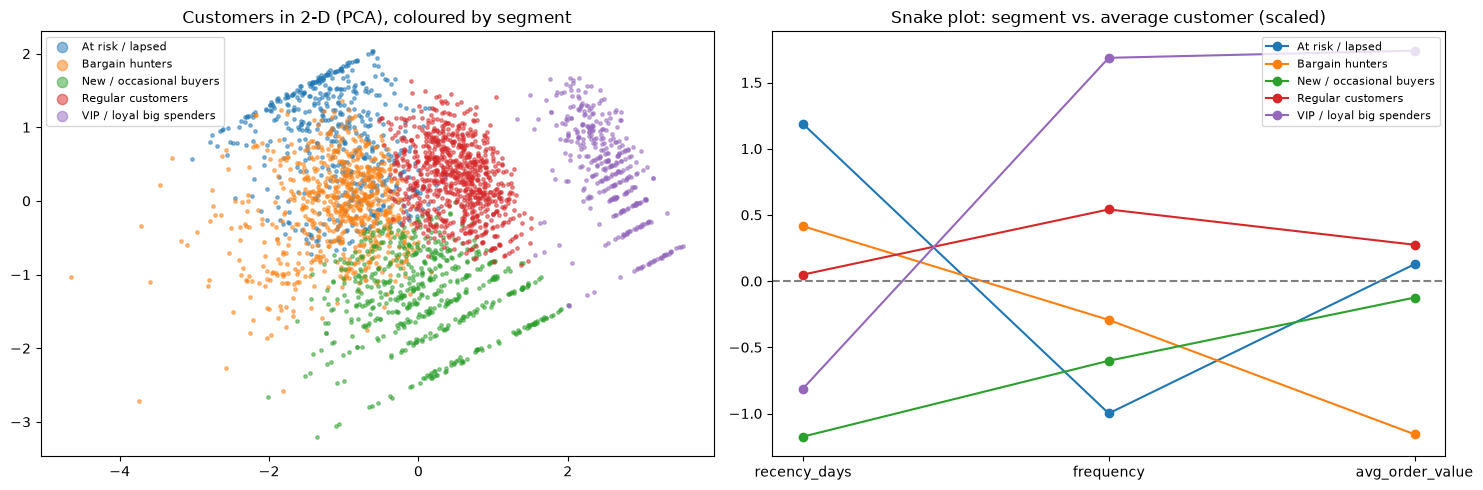

In [10]:
scaled = segmenter[:-1].transform(rfm[CLUSTER_FEATURES])   # all steps except KMeans = log + scale
coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, group_idx in rfm.groupby("segment_name").indices.items():
    axes[0].scatter(coords[group_idx, 0], coords[group_idx, 1], s=6, alpha=0.5, label=name)
axes[0].set_title("Customers in 2-D (PCA), coloured by segment")
axes[0].legend(markerscale=3, fontsize=8)

# Snake plot: average scaled value per segment (0 = typical customer)
snake = pd.DataFrame(scaled, columns=CLUSTER_FEATURES).groupby(rfm["segment_name"].values).mean()
for name, row in snake.iterrows():
    axes[1].plot(CLUSTER_FEATURES, row.values, "o-", label=name)
axes[1].axhline(0, color="grey", ls="--")
axes[1].set_title("Snake plot: segment vs. average customer (scaled)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8b. Sanity check against the classic "RFM score" method
Before machine learning, marketers scored each customer **1-5** on R, F and M using quintiles (5 = best), and used simple rules like *"R≥4 and F≥4 → Champions"*. Many companies still use this. It is a great **baseline**: if K-Means segments look nothing like these, investigate.

In [11]:
scores_rfm = pd.DataFrame(index=rfm.index)
scores_rfm["R"] = pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)  # recent = 5
scores_rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
scores_rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)


def classic_rfm_label(r: pd.Series) -> str:
    if r["R"] >= 4 and r["F"] >= 4 and r["M"] >= 4:
        return "Champions"
    if r["R"] <= 2 and r["F"] >= 3:
        return "Can't lose them"
    if r["R"] <= 2:
        return "Hibernating"
    if r["F"] <= 2:
        return "Promising / new"
    return "Loyal"


rfm["classic_rfm"] = scores_rfm.apply(classic_rfm_label, axis=1)
# Rows = our K-Means segments, columns = classic rules. Big numbers on matching names = consistent.
pd.crosstab(rfm["segment_name"], rfm["classic_rfm"])

classic_rfm,Can't lose them,Champions,Hibernating,Loyal,Promising / new
segment_name,,,,,
At risk / lapsed,59,0,379,0,72
Bargain hunters,253,0,201,132,159
New / occasional buyers,0,56,0,147,355
Regular customers,283,196,5,303,28
VIP / loyal big spenders,19,282,0,68,0


---
## 9. Check stability: would we get the same segments again?

If tiny changes in the data completely reshuffle the segments, marketing can't build campaigns on them.
**Stability test:** re-fit on random 80% subsamples and compare with the original labels using the **Adjusted Rand Index** (ARI: 1 = identical grouping, 0 = random).

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
ari_scores = []
for i in range(5):
    sample_idx = rng.choice(len(rfm), int(0.8 * len(rfm)), replace=False)
    sample = rfm.iloc[sample_idx][CLUSTER_FEATURES]
    refit = clone(segmenter).set_params(kmeans__random_state=i)   # clone = fresh, unfitted copy
    refit.fit(sample)                                               # (never refit the original model!)
    ari_scores.append(adjusted_rand_score(rfm["segment_id"].iloc[sample_idx], refit.predict(sample)))

print("ARI per run:", np.round(ari_scores, 3))
print(f"Mean stability (ARI): {np.mean(ari_scores):.3f}  ->",
      "stable, safe to use" if np.mean(ari_scores) > 0.8 else "unstable, revisit features or k")

ARI per run: [0.995 0.946 0.974 0.966 0.989]
Mean stability (ARI): 0.974  -> stable, safe to use


---
## 10. Save the model and assign new customers

Segmentation is not a one-off analysis: every week, **new** customers must be put into the right segment automatically.
We save the fitted pipeline plus the segment names, then use them on next month's order log.

In [13]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="segmentation_"))
joblib.dump(segmenter, ARTIFACT_DIR / "segmenter.joblib")
(ARTIFACT_DIR / "segment_names.json").write_text(json.dumps(
    {int(k): v for k, v in profile["segment_name"].items()}, indent=2))
print("Saved:", [p.name for p in ARTIFACT_DIR.iterdir()])


def assign_segments(order_log: pd.DataFrame, snapshot: pd.Timestamp, artifact_dir: Path) -> pd.DataFrame:
    """Production function: raw orders in, one segment per customer out."""
    model = joblib.load(artifact_dir / "segmenter.joblib")
    names = {int(k): v for k, v in json.loads((artifact_dir / "segment_names.json").read_text()).items()}
    features = build_rfm(order_log, snapshot)                 # SAME feature code as training
    features["segment_id"] = model.predict(features[CLUSTER_FEATURES])
    features["segment_name"] = features["segment_id"].map(names)
    return features


new_orders = simulate_orders(n_customers=500, seed=99)
assigned = assign_segments(new_orders, SNAPSHOT_DATE + pd.Timedelta(days=30), ARTIFACT_DIR)
assigned["segment_name"].value_counts()

2026-10-21 15:54:05,667 | INFO | Found 200 refund rows


Saved: ['segmenter.joblib', 'segment_names.json']


segment_name
Bargain hunters             161
At risk / lapsed            144
Regular customers           134
VIP / loyal big spenders     60
Name: count, dtype: int64

---
## 11. Turn segments into actions

A segmentation is only valuable if each segment gets a **different action**. This mapping is what you hand to the marketing team.

In [14]:
PLAYBOOK = {
    "VIP / loyal big spenders": "Early access + personal account manager. Do NOT send discounts (they buy anyway).",
    "Regular customers": "Loyalty points and cross-sell recommendations.",
    "Bargain hunters": "Send sale alerts and bundle deals.",
    "New / occasional buyers": "Onboarding email series, 2nd-purchase coupon.",
    "At risk / lapsed": "Win-back campaign with a strong discount; survey why they left.",
}
summary = (assigned.groupby("segment_name")
           .agg(customers=("frequency", "size"), median_spend=("monetary", "median"))
           .assign(action=lambda t: [PLAYBOOK.get(n.split(" (")[0], "Review manually") for n in t.index]))
pd.set_option("display.max_colwidth", 90)
summary.round(0)

,customers,median_spend,action
segment_name,,,
At risk / lapsed,144,119.0,Win-back campaign with a strong discount; survey why they left.
Bargain hunters,161,113.0,Send sale alerts and bundle deals.
Regular customers,134,520.0,Loyalty points and cross-sell recommendations.
VIP / loyal big spenders,60,3638.0,Early access + personal account manager. Do NOT send discounts (they buy anyway).


---
## 12. Summary

| Industry practice | What we did |
|---|---|
| Start from raw logs | Aggregated orders into RFM features |
| Clean known issues | Excluded refunds from behaviour features |
| Fix skew and scale | `log1p` + `StandardScaler` inside a pipeline |
| Choose k with metrics **and** business sense | Elbow, silhouette, Calinski-Harabasz, limited to 3-7 |
| Make clusters understandable | Profiles, revenue share, human names |
| Check robustness | Bootstrap stability with ARI |
| Productionise | Saved pipeline + names, `assign_segments()` for new customers |
| Deliver value | Segment → action playbook |

### Practice exercises
1. Add a feature: `tenure_days` (days since **first** order). Do the segments change?
1. Put `monetary` back into `CLUSTER_FEATURES`. Do the segments become harder to name? Why?
1. **Segment migration:** run `assign_segments` on the same customers one month later and use `pd.crosstab(old, new)` to see who moved from "Regular" to "At risk". Retention teams watch this table closely.
2. Try `sklearn.mixture.GaussianMixture` instead of KMeans. It gives a *probability* of belonging to each segment.
3. Re-run the stability test with `k = 8`. Is it less stable? Why might that be?

### Related notebooks
- Algorithms: `01_clustering.ipynb`, `02_dimensionality_reduction.ipynb`
- Supervised version of a customer problem: `../01_supervised/14_industry_churn_prediction.ipynb`